In [1]:

import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow", "numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "pillow"])


0

In [2]:
import os
import json
import time
import zipfile
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)
np.random.seed(42)

physical_devices = tf.config.list_physical_devices("GPU")

gpu_detected = len(physical_devices) > 0

if gpu_detected:
    gpu_name = tf.config.experimental.get_device_details(
        physical_devices[0]
    ).get("device_name", "Unknown GPU")
    
    print(f"TensorFlow Version: {tf.__version__}")
    print(f"GPU Available: True")
    print(f"GPU Count: {len(physical_devices)}")
    print(f"GPU Name: {gpu_name}")

    try:
        keras.mixed_precision.set_global_policy("mixed_float16")
        print("Mixed Precision: Enabled")
    except Exception:
        print("Mixed Precision: Not Enabled")
else:
    gpu_name = "CPU"
    print(f"TensorFlow Version: {tf.__version__}")
    print("GPU Available: False")
    print("GPU Name: CPU")

TensorFlow Version: 2.20.0
GPU Available: True
GPU Count: 2
GPU Name: Tesla T4
Mixed Precision: Enabled


In [3]:

target_classes_raw = ['glioma', 'meningioma', 'pituitary', 'notumor', 'no tumor', 'no_tumor']
required_classes = ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor']
dataset_path = '/kaggle/input'

filepaths = []
labels = []
dataset_origins = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            parent_dir = os.path.basename(root).lower()
            if any(tc in parent_dir for tc in target_classes_raw):
                filepaths.append(os.path.join(root, file))
                
                if 'glioma' in parent_dir:
                    labels.append('Glioma')
                elif 'meningioma' in parent_dir:
                    labels.append('Meningioma')
                elif 'pituitary' in parent_dir:
                    labels.append('Pituitary')
                elif 'notumor' in parent_dir or 'no tumor' in parent_dir or 'no_tumor' in parent_dir:
                    labels.append('No Tumor')
                
                if 'train' in root.lower():
                    dataset_origins.append('train')
                elif 'test' in root.lower() or 'val' in root.lower():
                    dataset_origins.append('test')
                else:
                    dataset_origins.append('unknown')

df_full = pd.DataFrame({
    'filepath': filepaths,
    'label': labels,
    'origin': dataset_origins
})

print(f"Discovered {len(df_full)} potential image files.")

Discovered 7200 potential image files.


In [4]:

valid_filepaths = []
valid_labels = []
valid_origins = []
file_hashes = set()
corrupt_count = 0
duplicate_count = 0

for idx, row in df_full.iterrows():
    try:
        with Image.open(row['filepath']) as img:
            img.verify()
        
        with open(row['filepath'], 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
            
        if file_hash in file_hashes:
            duplicate_count += 1
            continue
            
        file_hashes.add(file_hash)
        valid_filepaths.append(row['filepath'])
        valid_labels.append(row['label'])
        valid_origins.append(row['origin'])
        
    except Exception:
        corrupt_count += 1

df_clean = pd.DataFrame({
    'filepath': valid_filepaths,
    'label': valid_labels,
    'origin': valid_origins
})

print(f"Removed {corrupt_count} corrupt files.")
print(f"Removed {duplicate_count} duplicate files.")
print(f"Remaining valid files: {len(df_clean)}")

Removed 0 corrupt files.
Removed 187 duplicate files.
Remaining valid files: 7013


In [5]:

class_to_index = {cls: idx for idx, cls in enumerate(required_classes)}
df_clean['label_index'] = df_clean['label'].map(class_to_index)

if 'train' in df_clean['origin'].values and 'test' in df_clean['origin'].values:
    df_train_full = df_clean[df_clean['origin'] == 'train'].copy()
    df_test = df_clean[df_clean['origin'] == 'test'].copy()
    
    df_train, df_val = train_test_split(
        df_train_full, 
        test_size=0.1, 
        stratify=df_train_full['label'], 
        random_state=42
    )
else:
    df_train_full, df_test = train_test_split(
        df_clean, 
        test_size=0.1, 
        stratify=df_clean['label'], 
        random_state=42
    )
    df_train, df_val = train_test_split(
        df_train_full, 
        test_size=0.1 / 0.9, 
        stratify=df_train_full['label'], 
        random_state=42
    )

print(f"Train Set: {len(df_train)} samples")
print(f"Validation Set: {len(df_val)} samples")
print(f"Test Set: {len(df_test)} samples")

Train Set: 4886 samples
Validation Set: 543 samples
Test Set: 1584 samples


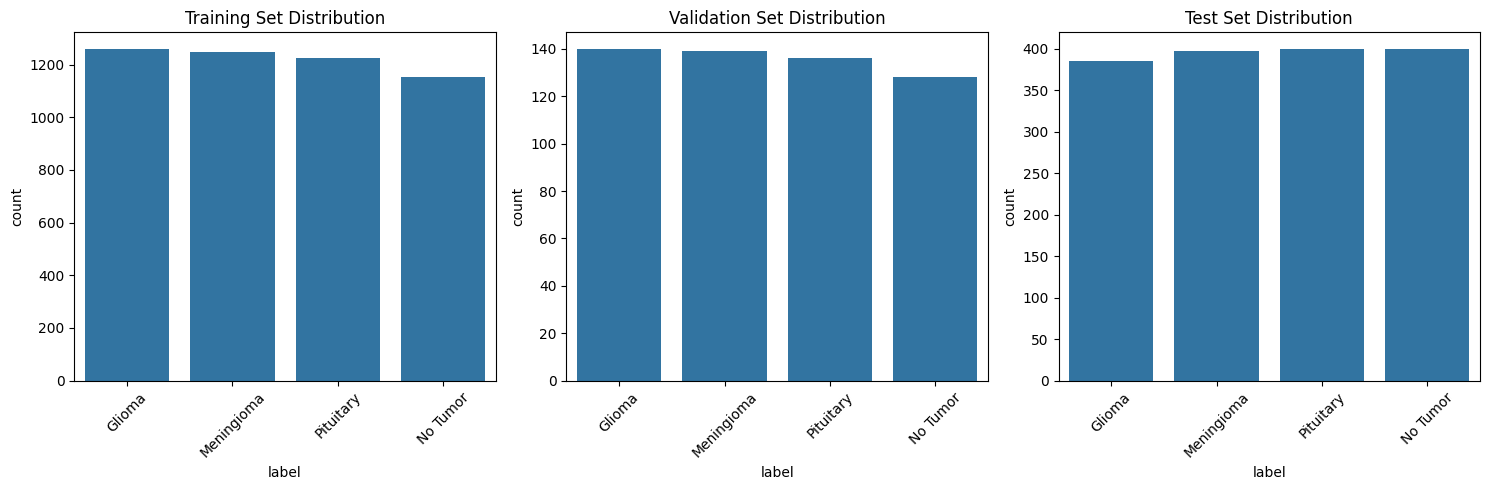

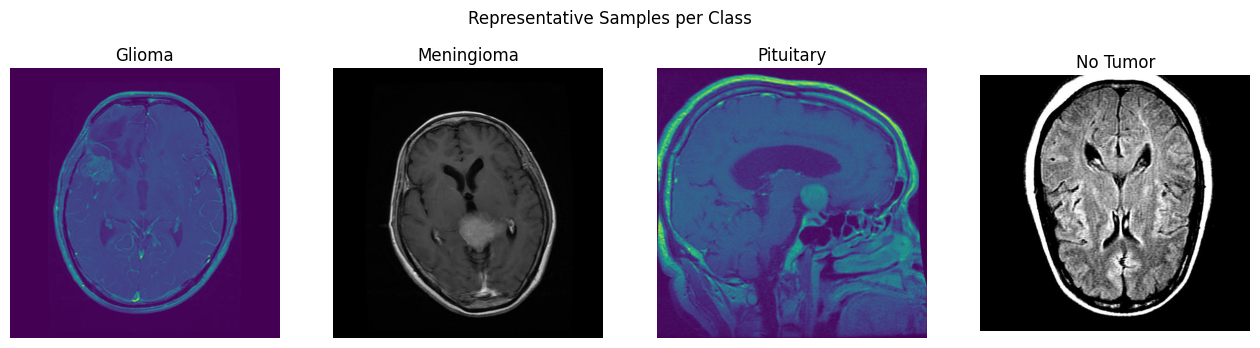

In [6]:

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
sns.countplot(data=df_train, x='label', order=required_classes)
plt.title('Training Set Distribution')
plt.xticks(rotation=45)

plt.subplot(1, 3, 2)
sns.countplot(data=df_val, x='label', order=required_classes)
plt.title('Validation Set Distribution')
plt.xticks(rotation=45)

plt.subplot(1, 3, 3)
sns.countplot(data=df_test, x='label', order=required_classes)
plt.title('Test Set Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for idx, cls in enumerate(required_classes):
    sample_row = df_train[df_train['label'] == cls].iloc[0]
    img = Image.open(sample_row['filepath'])
    axes[idx].imshow(img)
    axes[idx].set_title(cls)
    axes[idx].axis('off')
plt.suptitle('Representative Samples per Class')
plt.show()

In [7]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.05),
    keras.layers.RandomTranslation(0.05, 0.05),
])

I0000 00:00:1788359529.175664     152 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788359529.178874     152 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [8]:

batch_size = 32 if gpu_detected else 16
img_size = (299, 299)
AUTOTUNE = tf.data.AUTOTUNE

def process_path(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, img_size)
    label_oh = tf.one_hot(label, depth=len(required_classes))
    return img, label_oh

def create_dataset(df, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df['filepath'].values, df['label_index'].values))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (keras.applications.xception.preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = create_dataset(df_train, augment=True, shuffle=True)
val_ds = create_dataset(df_val, augment=False, shuffle=False)
test_ds = create_dataset(df_test, augment=False, shuffle=False)

In [9]:

base_model = keras.applications.Xception(
    weights='imagenet',
    include_top=False,
    input_shape=img_size + (3,)
)
base_model.trainable = False

inputs = keras.Input(shape=img_size + (3,))
x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.4)(x)
outputs = keras.layers.Dense(len(required_classes), activation='softmax', dtype='float32')(x)

model = keras.Model(inputs, outputs)
model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,869,676 (79.61 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

In [10]:

class TimeTrackingCallback(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []
        self.total_epochs = self.params['epochs']

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.epoch_start_time
        self.epoch_times.append(elapsed)
        avg_time = sum(self.epoch_times) / len(self.epoch_times)
        remaining_epochs = self.total_epochs - (epoch + 1)
        remaining_time = avg_time * remaining_epochs
        
        print(f"\n--- Epoch {epoch + 1} completed in {elapsed:.2f}s | Est. time remaining for stage: {remaining_time:.2f}s ---")


In [11]:

class_weights_array = compute_class_weight('balanced', classes=np.unique(df_train['label_index']), y=df_train['label_index'])
class_weights_dict = {i: w for i, w in enumerate(class_weights_array)}

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage1 = [
    keras.callbacks.ModelCheckpoint('brain_tumor_stage1.keras', save_best_only=True, monitor='val_accuracy'),
    keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    TimeTrackingCallback()
]

epochs_stage1 = 10
start_time_stage1 = time.time()

history_stage1 = model.fit(
    train_ds,
    epochs=epochs_stage1,
    validation_data=val_ds,
    class_weight=class_weights_dict,
    callbacks=callbacks_stage1,
    verbose=1
)

duration_stage1 = time.time() - start_time_stage1

Epoch 1/10


I0000 00:00:1788359628.313693     224 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 679ms/step - accuracy: 0.6151 - loss: 0.9602
--- Epoch 1 completed in 204.50s | Est. time remaining for stage: 1840.54s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 205s 1s/step - accuracy: 0.7294 - loss: 0.7437 - val_accuracy: 0.8195 - val_loss: 0.5212
Epoch 2/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.8388 - loss: 0.4819
--- Epoch 2 completed in 76.13s | Est. time remaining for stage: 1122.54s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 76s 497ms/step - accuracy: 0.8397 - loss: 0.4700 - val_accuracy: 0.8508 - val_loss: 0.4497
Epoch 3/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 520ms/step - accuracy: 0.8461 - loss: 0.4264
--- Epoch 3 completed in 81.84s | Est. time remaining for stage: 845.77s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 534ms/step - accuracy: 0.8473 - loss: 0.4210 - val_accuracy: 0.8674 - val_loss: 0.4091
Epoch 4/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 530ms/step - accuracy: 0.8601 - loss: 0.3935
--- Epoch 4 completed in 82.67s | Est. time remaining for stage: 66

In [13]:

base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage2 = [
    keras.callbacks.ModelCheckpoint('brain_tumor_xception_final.keras', save_best_only=True, monitor='val_accuracy'),
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=2, min_lr=1e-7),
    TimeTrackingCallback()
]

epochs_stage2 = 3
start_time_stage2 = time.time()

history_stage2 = model.fit(
    train_ds,
    epochs=epochs_stage2,
    validation_data=val_ds,
    class_weight=class_weights_dict,
    callbacks=callbacks_stage2,
    verbose=1
)

duration_stage2 = time.time() - start_time_stage2
total_training_duration = duration_stage1 + duration_stage2


Epoch 1/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 750ms/step - accuracy: 0.8998 - loss: 0.2754
--- Epoch 1 completed in 210.43s | Est. time remaining for stage: 420.85s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 210s 1s/step - accuracy: 0.9020 - loss: 0.2677 - val_accuracy: 0.9171 - val_loss: 0.2564 - learning_rate: 1.0000e-05
Epoch 2/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.9197 - loss: 0.2303
--- Epoch 2 completed in 82.18s | Est. time remaining for stage: 146.31s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 536ms/step - accuracy: 0.9202 - loss: 0.2199 - val_accuracy: 0.9282 - val_loss: 0.2204 - learning_rate: 1.0000e-05
Epoch 3/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.9371 - loss: 0.1780
--- Epoch 3 completed in 81.40s | Est. time remaining for stage: 0.00s ---
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 531ms/step - accuracy: 0.9333 - loss: 0.1802 - val_accuracy: 0.9392 - val_loss: 0.1977 - learning_rate: 1.0000e-05


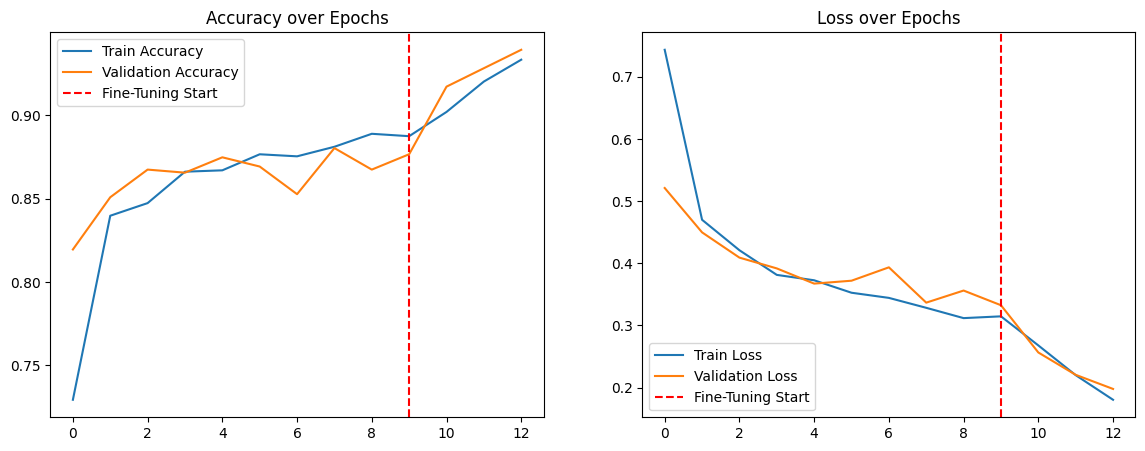

In [14]:

acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_stage1.history['accuracy'])-1, color='r', linestyle='--', label='Fine-Tuning Start')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history_stage1.history['loss'])-1, color='r', linestyle='--', label='Fine-Tuning Start')
plt.title('Loss over Epochs')
plt.legend()
plt.show()

50/50 ━━━━━━━━━━━━━━━━━━━━ 57s 737ms/step

Test Accuracy: 0.9091
Macro F1 Score: 0.9067
Weighted F1 Score: 0.9072

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.94      0.78      0.86       386
  Meningioma       0.86      0.86      0.86       398
   Pituitary       0.93      0.98      0.96       400
    No Tumor       0.91      1.00      0.95       400

    accuracy                           0.91      1584
   macro avg       0.91      0.91      0.91      1584
weighted avg       0.91      0.91      0.91      1584



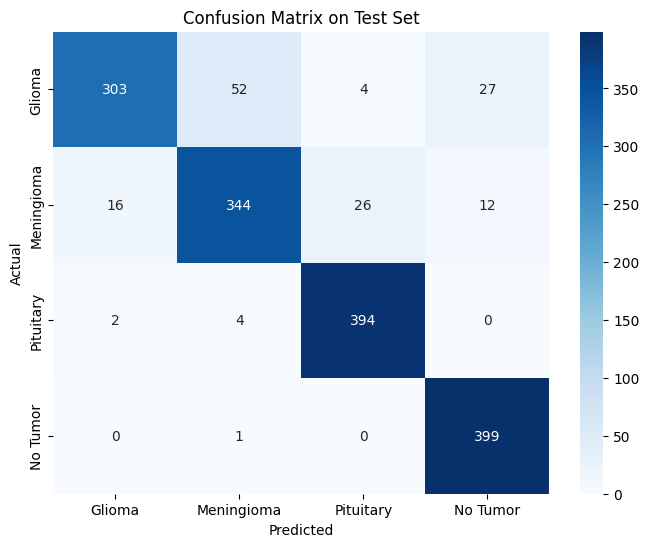

In [15]:

best_model = keras.models.load_model('brain_tumor_xception_final.keras')

y_true = df_test['label_index'].values
y_pred_probs = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_pred_conf = np.max(y_pred_probs, axis=1)

test_accuracy = np.mean(y_true == y_pred)
macro_f1 = f1_score(y_true, y_pred, average='macro')
weighted_f1 = f1_score(y_true, y_pred, average='weighted')

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Weighted F1 Score: {weighted_f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=required_classes))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=required_classes, yticklabels=required_classes)
plt.title('Confusion Matrix on Test Set')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

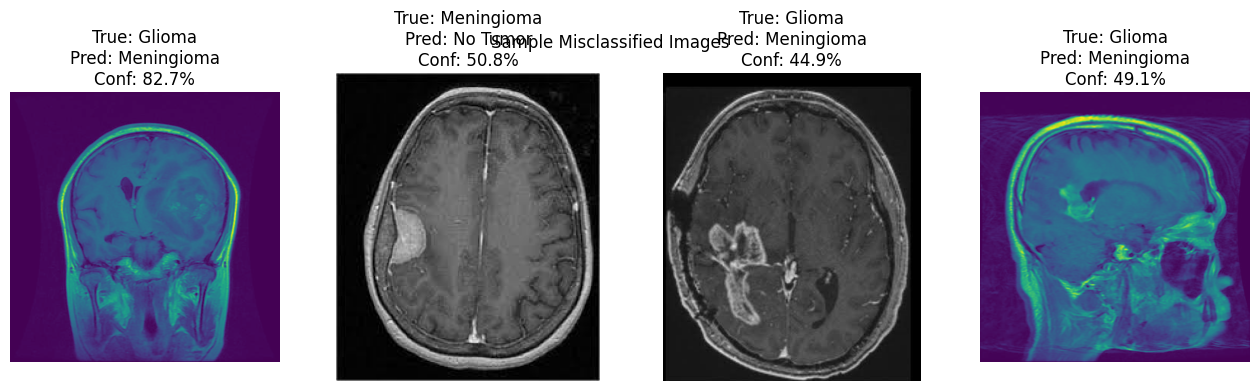

In [16]:

misclassified_indices = np.where(y_true != y_pred)[0]

if len(misclassified_indices) > 0:
    samples_to_show = min(4, len(misclassified_indices))
    selected_indices = np.random.choice(misclassified_indices, samples_to_show, replace=False)
    
    fig, axes = plt.subplots(1, samples_to_show, figsize=(16, 4))
    if samples_to_show == 1:
        axes = [axes]
        
    for i, idx in enumerate(selected_indices):
        img_path = df_test.iloc[idx]['filepath']
        true_label = required_classes[y_true[idx]]
        pred_label = required_classes[y_pred[idx]]
        conf = y_pred_conf[idx] * 100
        
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"True: {true_label}\nPred: {pred_label}\nConf: {conf:.1f}%")
        axes[i].axis('off')
        
    plt.suptitle('Sample Misclassified Images')
    plt.show()
else:
    print("No misclassified images found in the test set.")

In [17]:

inference_model = keras.models.load_model('brain_tumor_xception_final.keras')

sample_paths = df_test['filepath'].values[:3]
sample_true_labels = df_test['label'].values[:3]

print("Inference Verification:")
for path, true_label in zip(sample_paths, sample_true_labels):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, img_size)
    img = keras.applications.xception.preprocess_input(img)
    img = tf.expand_dims(img, axis=0)
    
    preds = inference_model.predict(img, verbose=0)[0]
    pred_idx = np.argmax(preds)
    pred_class = required_classes[pred_idx]
    confidence = preds[pred_idx] * 100
    
    print(f"Path: {os.path.basename(path)}")
    print(f"  Actual: {true_label}")
    print(f"  Predicted: {pred_class} ({confidence:.2f}%)")
    print("-" * 30)

Inference Verification:
Path: Te-pi_307.jpg
  Actual: Pituitary
  Predicted: Pituitary (96.80%)
------------------------------
Path: Te-pi_269.jpg
  Actual: Pituitary
  Predicted: Pituitary (98.22%)
------------------------------
Path: Te-pi_63.jpg
  Actual: Pituitary
  Predicted: Pituitary (87.16%)
------------------------------


In [19]:
metadata = {
    "model_name": "Brain_Tumor_Detection",
    "architecture": "Xception",
    "framework": "TensorFlow/Keras",
    "framework_version": str(tf.__version__),
    "python_version": str(sys.version.split(" ")[0]),
    "input_size": [299, 299, 3],
    "classes": [str(x) for x in required_classes],
    "class_to_index": {str(name): int(i) for name, i in class_to_index.items()},
    "preprocessing": "keras.applications.xception.preprocess_input",
    "augmentation": "RandomFlip, RandomRotation, RandomZoom, RandomTranslation",
    "model_artifact": "brain_tumor_xception_final.keras",
    "training_config": {
        "batch_size": int(batch_size),
        "best_epoch_stage1": int(np.argmax(history_stage1.history["val_accuracy"]) + 1),
        "best_epoch_stage2": int(np.argmax(history_stage2.history["val_accuracy"]) + 1),
        "training_duration_seconds": int(total_training_duration)
    },
    "metrics": {
        "test_accuracy": float(test_accuracy),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "best_val_accuracy": float(max(
            history_stage1.history["val_accuracy"] +
            history_stage2.history["val_accuracy"]
        ))
    },
    "hardware": {
        "gpu_used": bool(gpu_detected),
        "gpu_name": str(gpu_name)
    }
}

with open("metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("metadata.json successfully created.")

metadata.json successfully created.


In [21]:
#cell18
import importlib.metadata

packages = [
    "tensorflow",
    "keras",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "Pillow"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        try:
            version = importlib.metadata.version(package)
            f.write(f"{package}=={version}\n")
        except importlib.metadata.PackageNotFoundError:
            print(f"Package not found: {package}")

print("requirements.txt created successfully.")
print(open("requirements.txt").read())

requirements.txt created successfully.
tensorflow==2.20.0
keras==3.13.2
numpy==2.0.2
pandas==2.3.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
Pillow==11.3.0



In [22]:
#cell20
import os
import zipfile

zip_name = "brain_tumor_module.zip"

files_to_zip = [
    "brain_tumor_xception_final.keras",
    "metadata.json",
    "requirements.txt"
]

notebook_candidates = [
    "brain_tumor_xception.ipynb",
    "/kaggle/working/brain_tumor_xception.ipynb"
]

notebook_path = None

for candidate in notebook_candidates:
    if os.path.exists(candidate):
        notebook_path = candidate
        break

if notebook_path is not None:
    files_to_zip.insert(0, notebook_path)

missing_files = [f for f in files_to_zip if not os.path.exists(f)]

if missing_files:
    print("Missing files:")
    for f in missing_files:
        print(f" - {f}")
    raise FileNotFoundError("Required artifact is missing.")

with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_zip:
        zipf.write(file_path, arcname=os.path.basename(file_path))

print(f"Final ZIP created: {os.path.abspath(zip_name)}")
print("Files included:")

with zipfile.ZipFile(zip_name, "r") as zipf:
    for name in zipf.namelist():
        print(f" - {name}")

print("\nFINAL SUMMARY")
print(f"Dataset Size: {len(df_clean)}")
print(f"Train Size: {len(df_train)}")
print(f"Validation Size: {len(df_val)}")
print(f"Test Size: {len(df_test)}")
print(f"Model: Xception")
print(f"GPU: {gpu_name}")
print(f"Batch Size: {batch_size}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")
print(f"Training Time: {total_training_duration / 60:.2f} minutes")
print(f"Model Path: {os.path.abspath('brain_tumor_xception_final.keras')}")
print(f"Metadata Path: {os.path.abspath('metadata.json')}")
print(f"Requirements Path: {os.path.abspath('requirements.txt')}")
print(f"ZIP Path: {os.path.abspath(zip_name)}")

Final ZIP created: /kaggle/working/brain_tumor_module.zip
Files included:
 - brain_tumor_xception_final.keras
 - metadata.json
 - requirements.txt

FINAL SUMMARY
Dataset Size: 7013
Train Size: 4886
Validation Size: 543
Test Size: 1584
Model: Xception
GPU: Tesla T4
Batch Size: 32
Test Accuracy: 0.9091
Macro F1: 0.9067
Weighted F1: 0.9072
Training Time: 21.79 minutes
Model Path: /kaggle/working/brain_tumor_xception_final.keras
Metadata Path: /kaggle/working/metadata.json
Requirements Path: /kaggle/working/requirements.txt
ZIP Path: /kaggle/working/brain_tumor_module.zip
